# Real-Time Sensor Data & TimeGAN Visualizations


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('ggplot')


## 1. Generate Dummy Data for Simulation


In [5]:
# Function to generate synthetic & real data for our visualizations
def generate_data(n_samples=500, seq_len=24, n_features=6):
    # Simulated Real Data
    np.random.seed(42)
    time = np.arange(n_samples)
    
    # 6 Features: Temperature, Pressure, Humidity, Voltage, Vibration, RPM
    real_temp = np.sin(time / 10) * 10 + 50 + np.random.randn(n_samples) * 2
    real_press = np.cos(time / 10) * 5 + 30 + np.random.randn(n_samples) * 1
    real_hum = np.sin(time / 15) * 20 + 40 + np.random.randn(n_samples) * 3
    real_volt = np.cos(time / 8) * 2 + 12 + np.random.randn(n_samples) * 0.2
    real_vib = np.sin(time / 5) * 1 + 2 + np.random.randn(n_samples) * 0.1
    real_rpm = np.cos(time / 12) * 500 + 3000 + np.random.randn(n_samples) * 50
    
    real_data = np.stack([real_temp, real_press, real_hum, real_volt, real_vib, real_rpm], axis=1)
    
    # Simulated Synthetic Data (Adding some noise/slight offset)
    synth_data = real_data + np.random.randn(*real_data.shape) * [1.0, 0.5, 1.5, 0.1, 0.05, 25.0]
    
    return real_data, synth_data

real_data, synth_data = generate_data()
features = ['Temperature', 'Pressure', 'Humidity', 'Voltage', 'Vibration', 'RPM']
df_real = pd.DataFrame(real_data, columns=features)
df_synth = pd.DataFrame(synth_data, columns=features)

print("Data shape:", real_data.shape)


Data shape: (500, 6)


## 2. Real vs Synthetic Time-Series


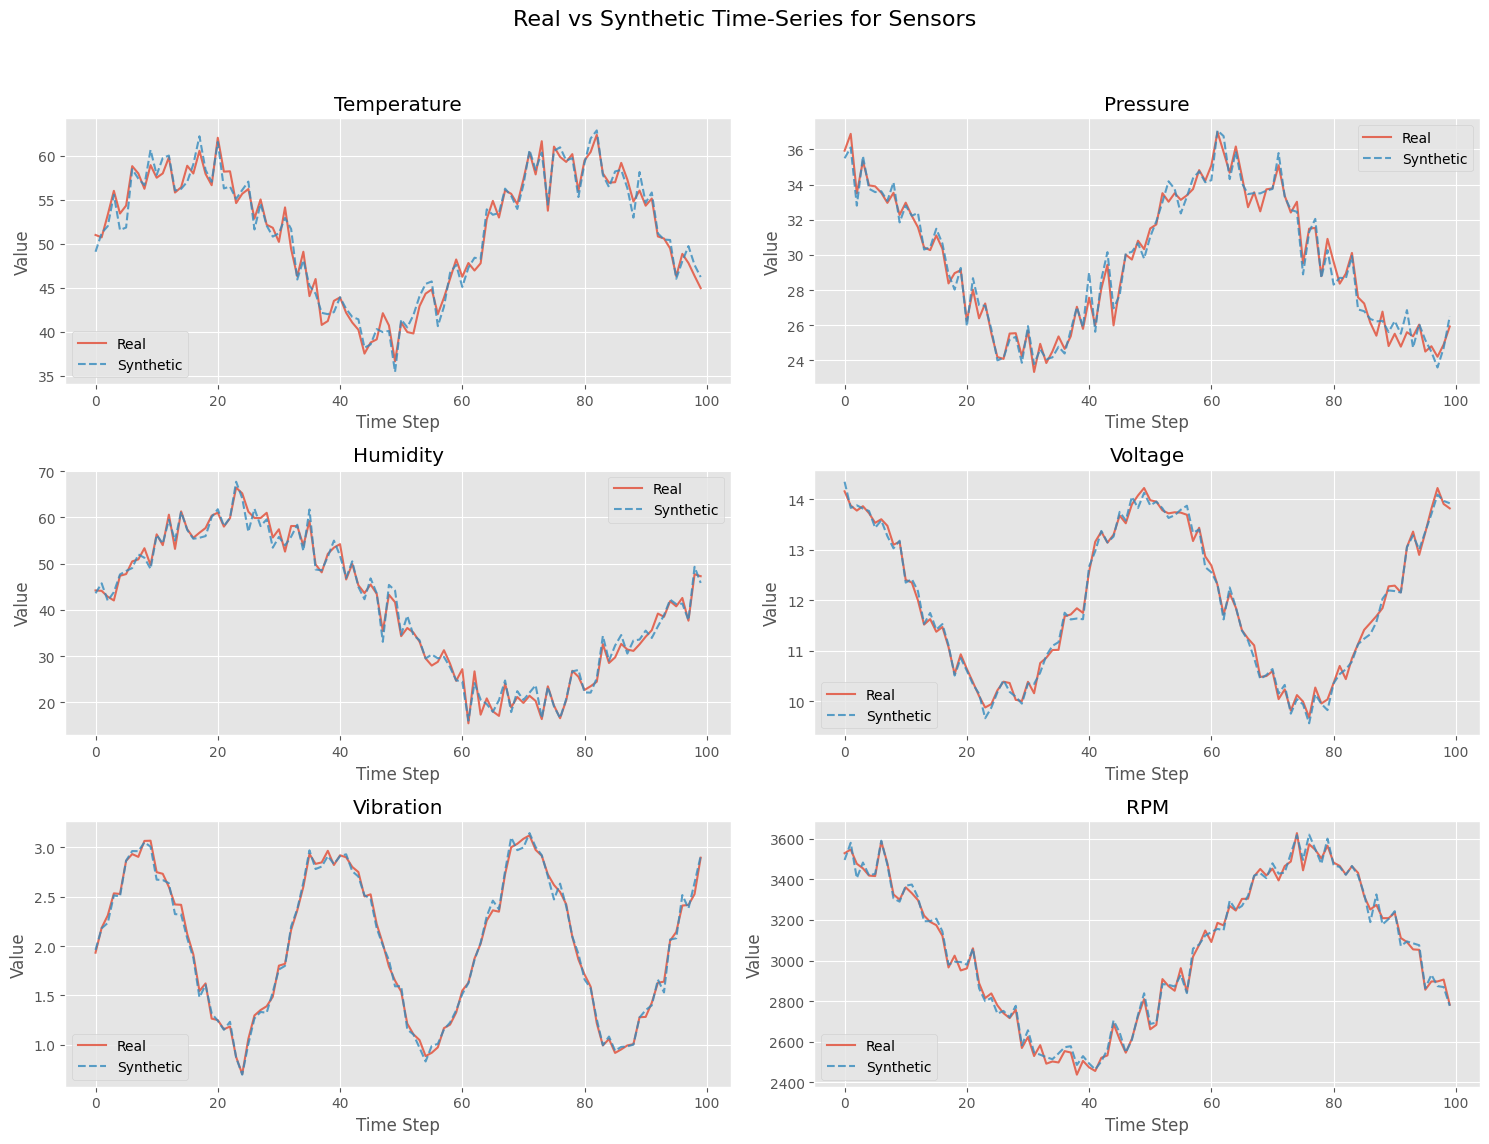

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Real vs Synthetic Time-Series for Sensors', fontsize=16)

axes = axes.flatten()
for i, feature in enumerate(features):
    axes[i].plot(df_real.index[:100], df_real[feature].iloc[:100], label='Real', alpha=0.8)
    axes[i].plot(df_synth.index[:100], df_synth[feature].iloc[:100], label='Synthetic', alpha=0.8, linestyle='--')
    axes[i].set_title(feature)
    axes[i].set_xlabel('Time Step')
    axes[i].set_ylabel('Value')
    axes[i].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


## 3. PCA Visualization


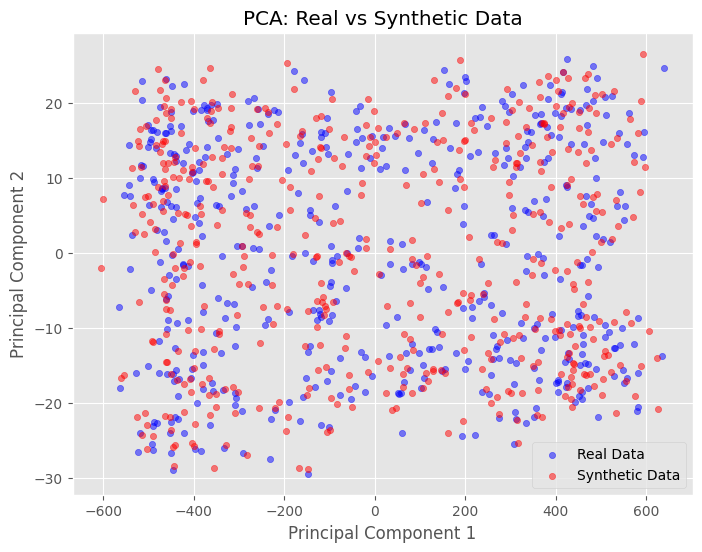

In [7]:
pca = PCA(n_components=2)
real_pca = pca.fit_transform(df_real)
synth_pca = pca.transform(df_synth)

plt.figure(figsize=(8, 6))
plt.scatter(real_pca[:, 0], real_pca[:, 1], c='blue', alpha=0.5, label='Real Data', s=20)
plt.scatter(synth_pca[:, 0], synth_pca[:, 1], c='red', alpha=0.5, label='Synthetic Data', s=20)
plt.title('PCA: Real vs Synthetic Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()


## 4. t-SNE Visualization


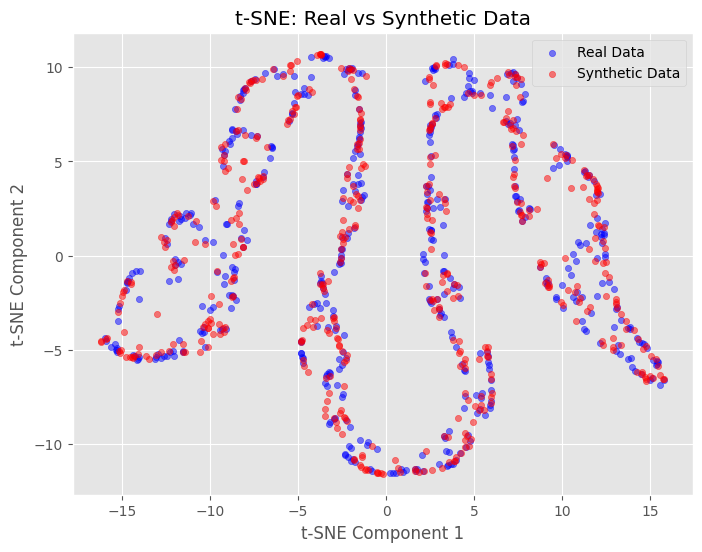

In [8]:
combined_data = np.vstack((df_real.values, df_synth.values))
labels = np.array(['Real'] * len(df_real) + ['Synthetic'] * len(df_synth))

tsne = TSNE(n_components=2, perplexity=30, n_iter=300, random_state=42)
tsne_results = tsne.fit_transform(combined_data)

plt.figure(figsize=(8, 6))
plt.scatter(tsne_results[labels == 'Real', 0], tsne_results[labels == 'Real', 1], c='blue', alpha=0.5, label='Real Data', s=20)
plt.scatter(tsne_results[labels == 'Synthetic', 0], tsne_results[labels == 'Synthetic', 1], c='red', alpha=0.5, label='Synthetic Data', s=20)
plt.title('t-SNE: Real vs Synthetic Data')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend()
plt.show()


## 5. Live Anomaly Score


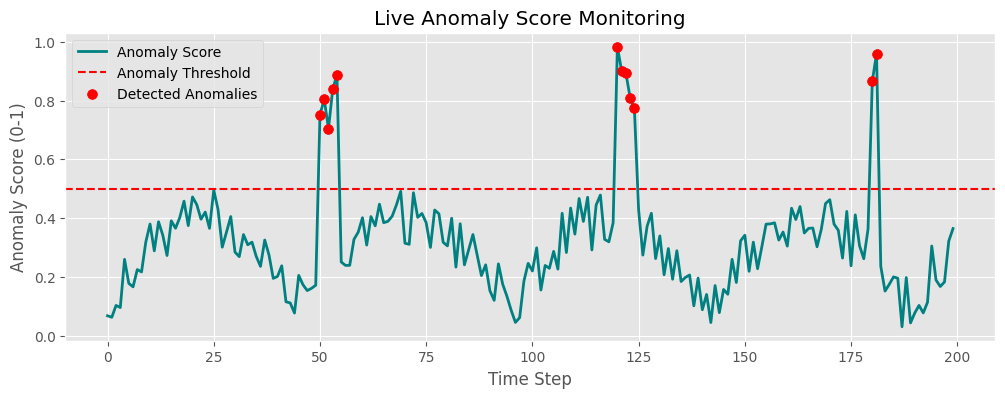

In [9]:
# Let's generate a mock anomaly score timeline
time_steps = np.arange(200)
anomaly_scores = np.abs(np.sin(time_steps / 15)) * 0.3 + np.random.rand(200) * 0.2

# Injecting anomalies
anomaly_scores[50:55] += 0.6
anomaly_scores[120:125] += 0.5
anomaly_scores[180:182] += 0.7

threshold = 0.5

plt.figure(figsize=(12, 4))
plt.plot(time_steps, anomaly_scores, label='Anomaly Score', color='teal', linewidth=2)
plt.axhline(y=threshold, color='red', linestyle='--', label='Anomaly Threshold')

# Highlight anomalies
anomalies = np.where(anomaly_scores > threshold)[0]
plt.scatter(anomalies, anomaly_scores[anomalies], color='red', s=50, zorder=5, label='Detected Anomalies')

plt.title('Live Anomaly Score Monitoring')
plt.xlabel('Time Step')
plt.ylabel('Anomaly Score (0-1)')
plt.legend()
plt.show()


## 6. Sensor Trend Graphs


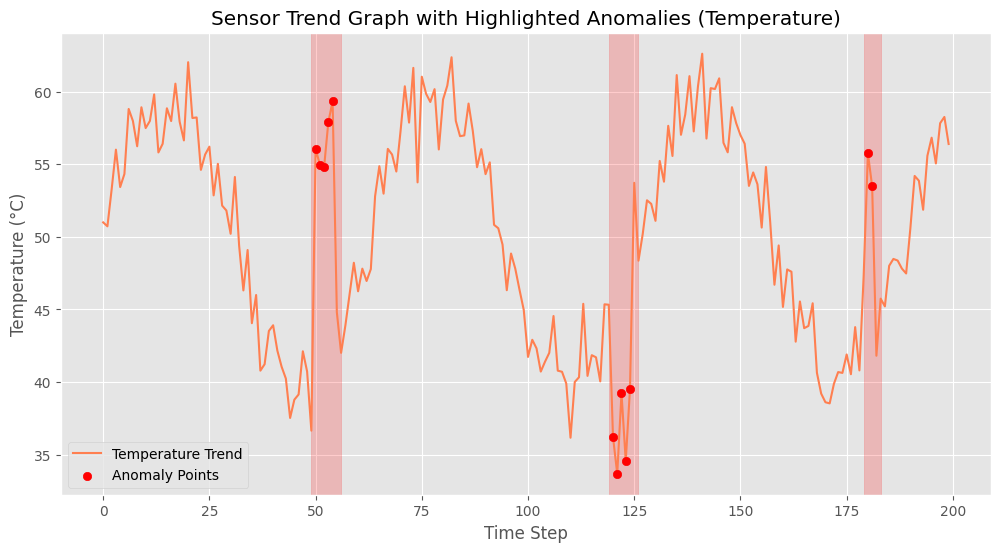

In [10]:
plt.figure(figsize=(12, 6))

# Let's plot Temperature and mark anomalies
temp_data = df_real['Temperature'].iloc[:200].copy()
# Add spikes corresponding to anomalies
temp_data.iloc[50:55] += 15
temp_data.iloc[120:125] -= 10
temp_data.iloc[180:182] += 12

plt.plot(time_steps, temp_data, label='Temperature Trend', color='coral')

# Mark anomalies on the trend graph
plt.scatter(anomalies, temp_data.iloc[anomalies], color='red', zorder=5, label='Anomaly Points')
plt.axvspan(49, 56, color='red', alpha=0.2)
plt.axvspan(119, 126, color='red', alpha=0.2)
plt.axvspan(179, 183, color='red', alpha=0.2)

plt.title('Sensor Trend Graph with Highlighted Anomalies (Temperature)')
plt.xlabel('Time Step')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()
